# L05 - Frequenzgang und Wobbelmessung (Lösung zu Aufgabe 05)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l05.m).

## Teilaufgabe a:    

In [13]:
% ##############################################################################
% ##  Loesung:  Frequenzgang und Wobbelmessung                                ##
% ##############################################################################

H = [1,-1] ; % Impulsantwort = Polynom H(z) = Zaehlerpolynom (H(z)) fuer FIR 
N = 32;      % Anzahl der Werte die ausgegeben werden sollen

## Teilaufgabe b: Amplituden- und Phasengang

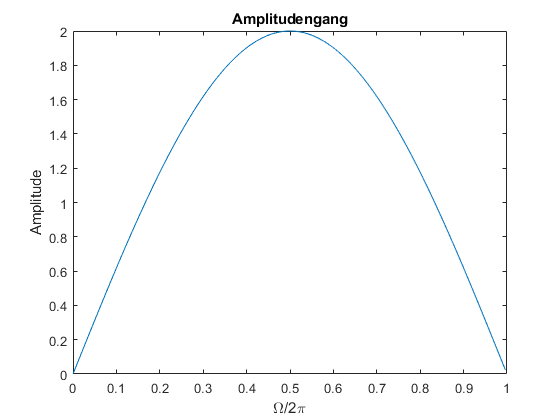

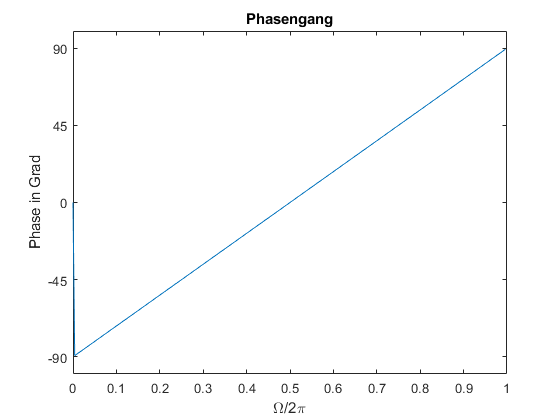

In [14]:
% #####  Teilaufgabe b:  Amplituden- und Phasengang  #####

[y,x] = freqz(H,1,256,'whole') ;

% # grafische Ausgabe # %
% Amplitudengang
figure;
plot(x/(2*pi),abs(y));
title('Amplitudengang'); 
xlabel('\Omega/2\pi'); 
ylabel('Amplitude');

% Phasengang
figure;
plot(x/(2*pi),-angle(y)/pi*180) ; % Achtung: -angle() wg. Phasengangdefinition
set(gca,'YTick',[-90,-45,0,45,90]);
title('Phasengang'); 
xlabel('\Omega/2\pi'); 
ylabel('Phase in Grad');

## Teilaufgabe c: Impulsantwort, Pol- Nullstellendiagramm

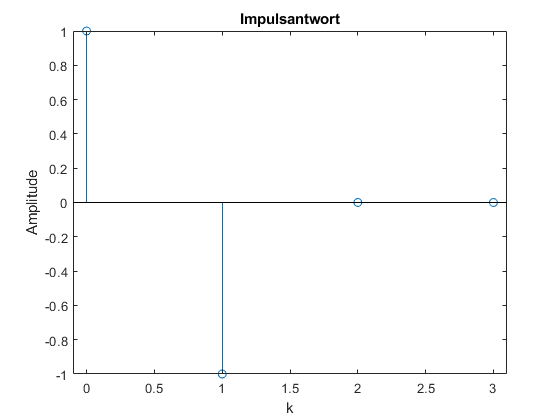

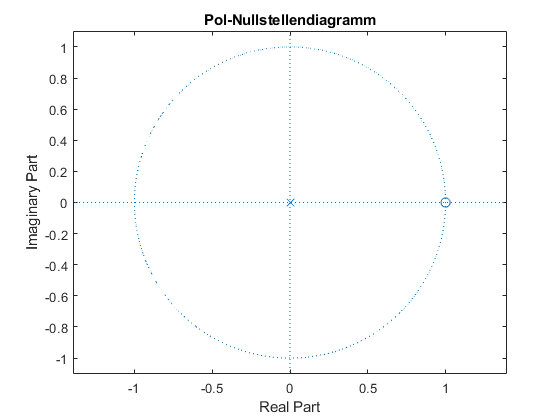

In [15]:
h  = impz(H,1,4); % 5 Abtastwerte
lh = length(h);

% # grafische Ausgabe # %
% Impulsantwort
figure;
stem(0:lh-1,h); 
axis([-0.1 3.1 -1 1]);
hold on; 
plot([-0.1,3.1],[0,0],'k'); 
hold off;
title('Impulsantwort'); 
xlabel('k'); 
ylabel('Amplitude') ;

% Pol- und Nullstellen in der z-Ebene
figure;
zplane(H,1);
title('Pol-Nullstellendiagramm');

## Teilaufgabe d: Wobbelmessung - Kosinuserregung

In [ ]:
lf = length(H) ;
k_wobbel = (0:N-1+2*(lf-1));    % Zum Wobbeln Sequenz der Laenge N+2*(lf-1)
n_wobbel = 0:N/2-1;             % normierte Frequenzen
erg = zeros(9,1);

for n = n_wobbel
    wobbel = cos(2*pi*n/N*k_wobbel) ;                 % Eigentliche Wobblemessung
    foo = conv(H,wobbel);                             % Es wird gewobbelt
    erg = [erg;max(abs(foo(1+(lf-1):length(foo)-(lf-1))))]; % ohne Einschwing-vorgaenge
end

[c,d] = freqz(H,1,N);  % Vergleich Wobbel - Amplitudengang

% # grafische Ausgabe # %
figure;
plot(2*n_wobbel/N,erg,'r+'); 
hold on;
plot(d/pi,abs(c),'b-') 
hold off;
title('+ Wobblemessung, - theoret. Amplitudengang'); 
xlabel('\Omega/\pi'); 
ylabel('Amplitude');

## Teilaufgabe e: Wobbelmessung - Exponentialerregung

In [ ]:
erg = [];
for n = n_wobbel
    wobbel = exp(1i*2*pi*n/N*k_wobbel);                 % Eigentliche Wobblemessung
    foo = conv(H,wobbel);                              % Es wird gewobbelt
    erg = [erg; max(abs(foo(1+(lf-1):length(foo)-(lf-1))))]; % ohne Einschwing-
                                                             % vorgaenge
end

% # grafische Ausgabe % #
figure;
plot(2*n_wobbel/N,erg,'r+');
hold on;
plot(d/pi,abs(c),'b-') 
hold off;
title('+ Wobblemessung, - theoret. Amplitudengang'); 
xlabel('\Omega/\pi'); 
ylabel('Amplitude');



## Teilaufgabe f: Sprungantwort

In [ ]:
epsilon = [zeros(10,1); ones(10,1)];
sprungantwort = conv(h,epsilon);
hdiff=diff(sprungantwort);

% # grafische Ausgabe # %
% Sprungfolge
figure;
stem((0:length(epsilon)-1)-10,epsilon);
title('Sprungfolge'); 
xlabel('k'); 
ylabel('\epsilon(k)');

% Sprungantwort
figure;
stem((0:length(sprungantwort)-1)-10,sprungantwort);
hold on; 
plot([-10,15],[0,0],'k'); 
hold off;
title('Sprungantwort'); 
xlabel('k'); 
ylabel('Amplitude');

% Impulsantwort
figure;
stem((0:length(hdiff)-1)-10,hdiff);
hold on; 
plot([-10,15],[0,0],'k'); 
hold off;
title('Impulsantwort'); 
xlabel('k'); 
ylabel('Amplitude');